statistics about my concert experiences

In [10]:
# first i imported the table from sql where i stored the data
import pandas as pd
import os
os.getcwd()

df= pd.read_csv(r'C:/Users/ahliy/Downloads/ks-projects-201612.csv/concertsjan.csv')

In [ ]:
# next i observed the data and converted it to datetime format 
print(df.head())
print(df.tail())
print(df.info())
df.isnull().sum()
df.columns=df.columns.str.lower().str.strip()
df.columns
df['dt']=pd.to_datetime(df['dt'],errors='coerce')
df.info()
df=df.dropna(subset=['dt'])
df['band'].value_counts()
df['venue'].value_counts()

              band                  venue                    dt
0  GRETA VAN FLEET       PPG PAINTS ARENA  0.011574074041666666
1           HALSEY   HAMMERSTEIN BALLROOM              01/15/25
2  PIERCE THE VEIL  MADISON SQUARE GARDEN              05/20/25
3           HALSEY            JONES BEACH              06/01/25
4  PIERCE THE VEIL              KIA FORUM              07/01/25
                        band                  venue       dt
27             ONE DIRECTION                METLIFE   8/5/15
28                      KCON      PRUDENTIAL CENTER   8/8/15
29           GRETA VAN FLEET  MADISON SQUARE GARDEN  9/12/23
30         TWENTY ONE PILOTS              UBS ARENA  9/18/24
31  SOUNDSIDE MUSIC FESTIVAL           SEASIDE PARK  9/29/24
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   band    32 non-null     object
 1   venue   32 non-null     object
 2  

C:\Users\ahliy\AppData\Local\Temp\ipykernel_13716\2765411065.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['dt']=pd.to_datetime(df['dt'],errors='coerce')


venue
MADISON SQUARE GARDEN        7
JONES BEACH                  5
UBS ARENA                    4
HARD ROCK CASINO             2
HAMMERSTEIN BALLROOM         1
LAS VEGAS CASINO             1
FENWAY PARK                  1
MAINE SAVINGS AMPITHEATER    1
KIA FORUM                    1
NASSUAU COLLESIUM            1
BARCLAYS CENTER              1
FOREST HILLS STADIUM         1
RADIO CITY MUSIC HALL        1
THE KNITTING FACTORY         1
METLIFE                      1
PRUDENTIAL CENTER            1
SEASIDE PARK                 1
Name: count, dtype: int64

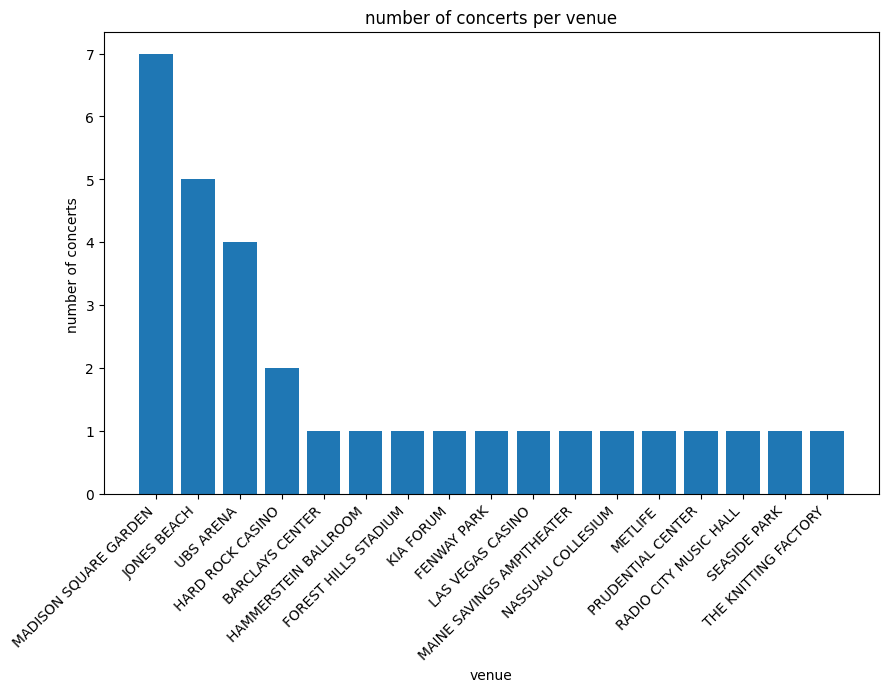

In [ ]:
# then i foudn the numeber of concerts attended by venue 
venue_count=(
    df.groupby('venue')
    .size()
    .reset_index(name='num_concerts')
    .sort_values('num_concerts',ascending=False)
    )
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.bar(venue_count['venue'],venue_count['num_concerts'])
plt.xticks(rotation=45,ha='right')
plt.title('number of concerts per venue')
plt.xlabel('venue')
plt.ylabel('number of concerts ')
plt.show()

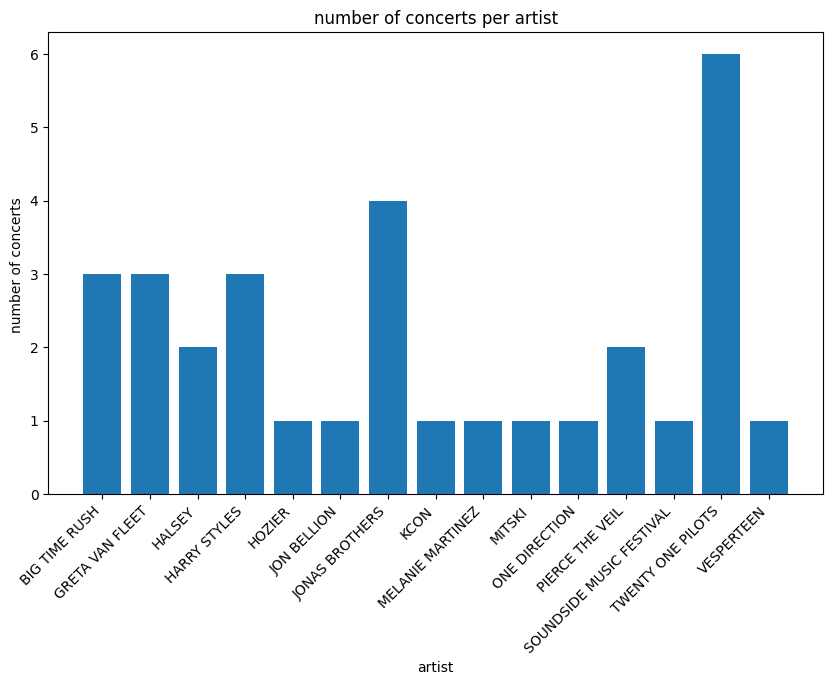

In [ ]:
# then the number of concerts attended by artist
artists_counts=(
    df.groupby('band')
    .size()
    .reset_index(name='num_concerts')

)

plt.figure(figsize=(10,6))
plt.bar(artists_counts['band'],artists_counts['num_concerts'])
plt.xticks(rotation=45,ha='right')
plt.title('number of concerts per artist')
plt.xlabel('artist')
plt.ylabel('number of concerts ')
plt.show()

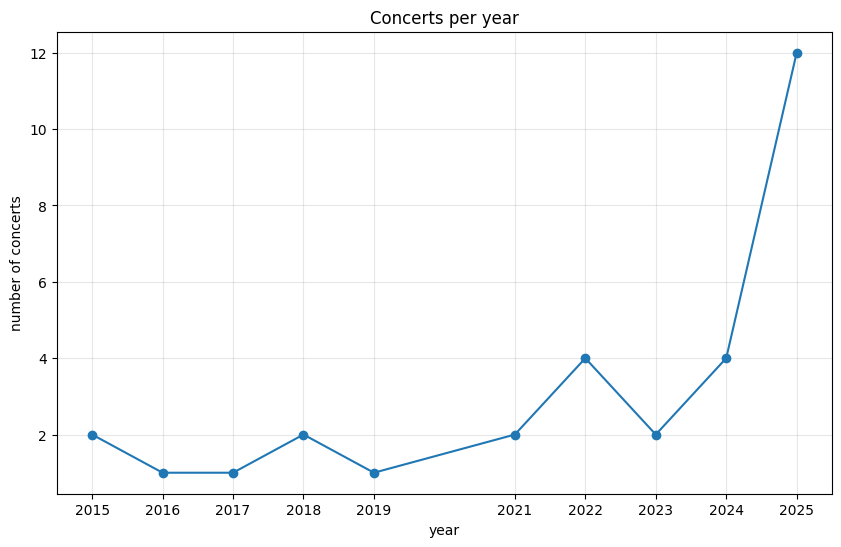

In [ ]:
# lastly i found the number of concerts attended by year while first extracting the year from the date to measure by that 
df["year"] = df["dt"].dt.year



concerts_per_year=(
    df.groupby('year')
    .size()
    .reset_index(name='num_concerts')
    .sort_values('year')
)
concerts_per_year
plt.figure(figsize=(10,6))
plt.plot(concerts_per_year['year'],
    
         concerts_per_year['num_concerts'],
         marker='o'
         )
plt.title('Concerts per year')
plt.xlabel('year')
plt.ylabel('number of concerts')
plt.xticks(concerts_per_year['year'])
plt.grid(True,alpha=.3)
plt.show()

I created a table in sql with my concert going stats, cleaned that data and then found three insights about my habits. I frequent madsion square garden a lot, I've seen twnety one pilots the most and I went to 12  cocnerts in 2025 which is the most of years prior.